# CNN Feature Visualization, Parameter Audit & Critical Analysis
**Deep Learning & Computer Vision — Practical Laboratory Assignment**

| | |
|---|---|
| **Student Name:** Mahnoor Hameed | **Registration No:** FA3-BAI-002 |
| **Course :** Computer Viion | **Submission Date:** 26th Nov 2026 |



## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate2d
from skimage import data, color, io, transform

plt.rcParams['figure.dpi'] = 110
np.set_printoptions(precision=3, suppress=True)

## Part I — Filter pipeline & visualization

### Input image
By default this uses a built-in test image with strong edges and textures. To use your own building photo (like Figure 2 of the handout), set `USE_UPLOAD = True` and upload it when prompted.

Image shape: (256, 256) | range: 0.01 - 1.0


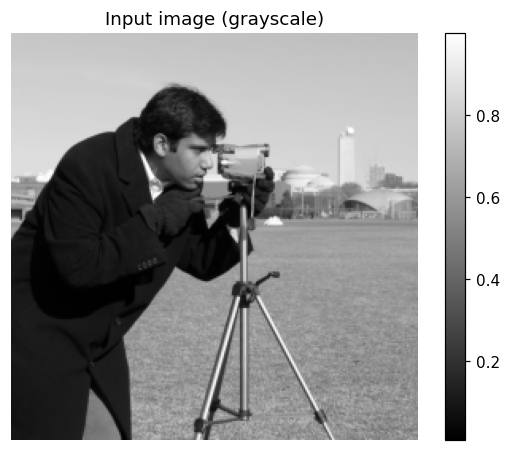

In [2]:
USE_UPLOAD = False   # set True in Colab to upload your own image

if USE_UPLOAD:
    from google.colab import files
    up = files.upload()
    img = io.imread(next(iter(up)))
    if img.ndim == 3:
        img = color.rgb2gray(img[..., :3])
    img = transform.resize(img, (256, 256), anti_aliasing=True)
else:
    img = data.camera().astype(np.float64) / 255.0       # 512x512 grayscale
    img = transform.resize(img, (256, 256), anti_aliasing=True)

img = img.astype(np.float64)
print("Image shape:", img.shape, "| range:", img.min().round(2), "-", img.max().round(2))
plt.imshow(img, cmap='gray'); plt.title("Input image (grayscale)"); plt.axis('off'); plt.colorbar(); plt.show()

### Step 1 — Five 3×3 kernels
Naming note: the handout calls the first filter "Horizontal Edge Detector (Sobel-X/Prewitt)". To make the name match the behaviour, kernel 1 responds to **horizontal edges** (intensity changes along the vertical direction) and kernel 2 to **vertical edges**. (In the textbook convention these are Sobel-Y and Sobel-X respectively.)

In [3]:
kernels = {
    "Horizontal Edge (Sobel)": np.array([[-1, -2, -1],
                                         [ 0,  0,  0],
                                         [ 1,  2,  1]], dtype=float),
    "Vertical Edge (Sobel)":   np.array([[-1, 0, 1],
                                         [-2, 0, 2],
                                         [-1, 0, 1]], dtype=float),
    "Sharpen":                 np.array([[ 0, -1,  0],
                                         [-1,  5, -1],
                                         [ 0, -1,  0]], dtype=float),
    "Box Blur":                np.ones((3, 3)) / 9.0,
    "Emboss":                  np.array([[-2, -1, 0],
                                         [-1,  1, 1],
                                         [ 0,  1, 2]], dtype=float),
}
for n, k in kernels.items():
    print(n, "\n", k, "\n")

Horizontal Edge (Sobel) 
 [[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]] 

Vertical Edge (Sobel) 
 [[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]] 

Sharpen 
 [[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]] 

Box Blur 
 [[0.111 0.111 0.111]
 [0.111 0.111 0.111]
 [0.111 0.111 0.111]] 

Emboss 
 [[-2. -1.  0.]
 [-1.  1.  1.]
 [ 0.  1.  2.]] 



### Step 2 — Four-stage execution (A: conv, B: ReLU, C: max-pool, D: avg-pool)

In [4]:
def conv2d(x, k):
    # CNN 'convolution' = cross-correlation; zero padding, 'same' output size, stride 1
    return correlate2d(x, k, mode='same', boundary='fill', fillvalue=0)

def relu(x):
    return np.maximum(0, x)

def pool2d(x, size=2, stride=2, mode='max'):
    H, W = x.shape
    oh, ow = (H - size)//stride + 1, (W - size)//stride + 1
    out = np.zeros((oh, ow))
    for i in range(oh):
        for j in range(ow):
            win = x[i*stride:i*stride+size, j*stride:j*stride+size]
            out[i, j] = win.max() if mode == 'max' else win.mean()
    return out

results = {}
for name, k in kernels.items():
    A = conv2d(img, k)
    B = relu(A)
    C_ = pool2d(B, mode='max')
    D = pool2d(B, mode='avg')
    results[name] = dict(A=A, B=B, C=C_, D=D)
    print(f"{name:26s} A{A.shape}  B{B.shape}  C{C_.shape}  D{D.shape}")

Horizontal Edge (Sobel)    A(256, 256)  B(256, 256)  C(128, 128)  D(128, 128)
Vertical Edge (Sobel)      A(256, 256)  B(256, 256)  C(128, 128)  D(128, 128)
Sharpen                    A(256, 256)  B(256, 256)  C(128, 128)  D(128, 128)
Box Blur                   A(256, 256)  B(256, 256)  C(128, 128)  D(128, 128)
Emboss                     A(256, 256)  B(256, 256)  C(128, 128)  D(128, 128)


### Step 3 — Unified 5 × 4 grid
Column A uses a diverging colormap centred on 0 (so negative values are visible); B, C, D share the same 0→max scale within each row for consistent intensity comparison.

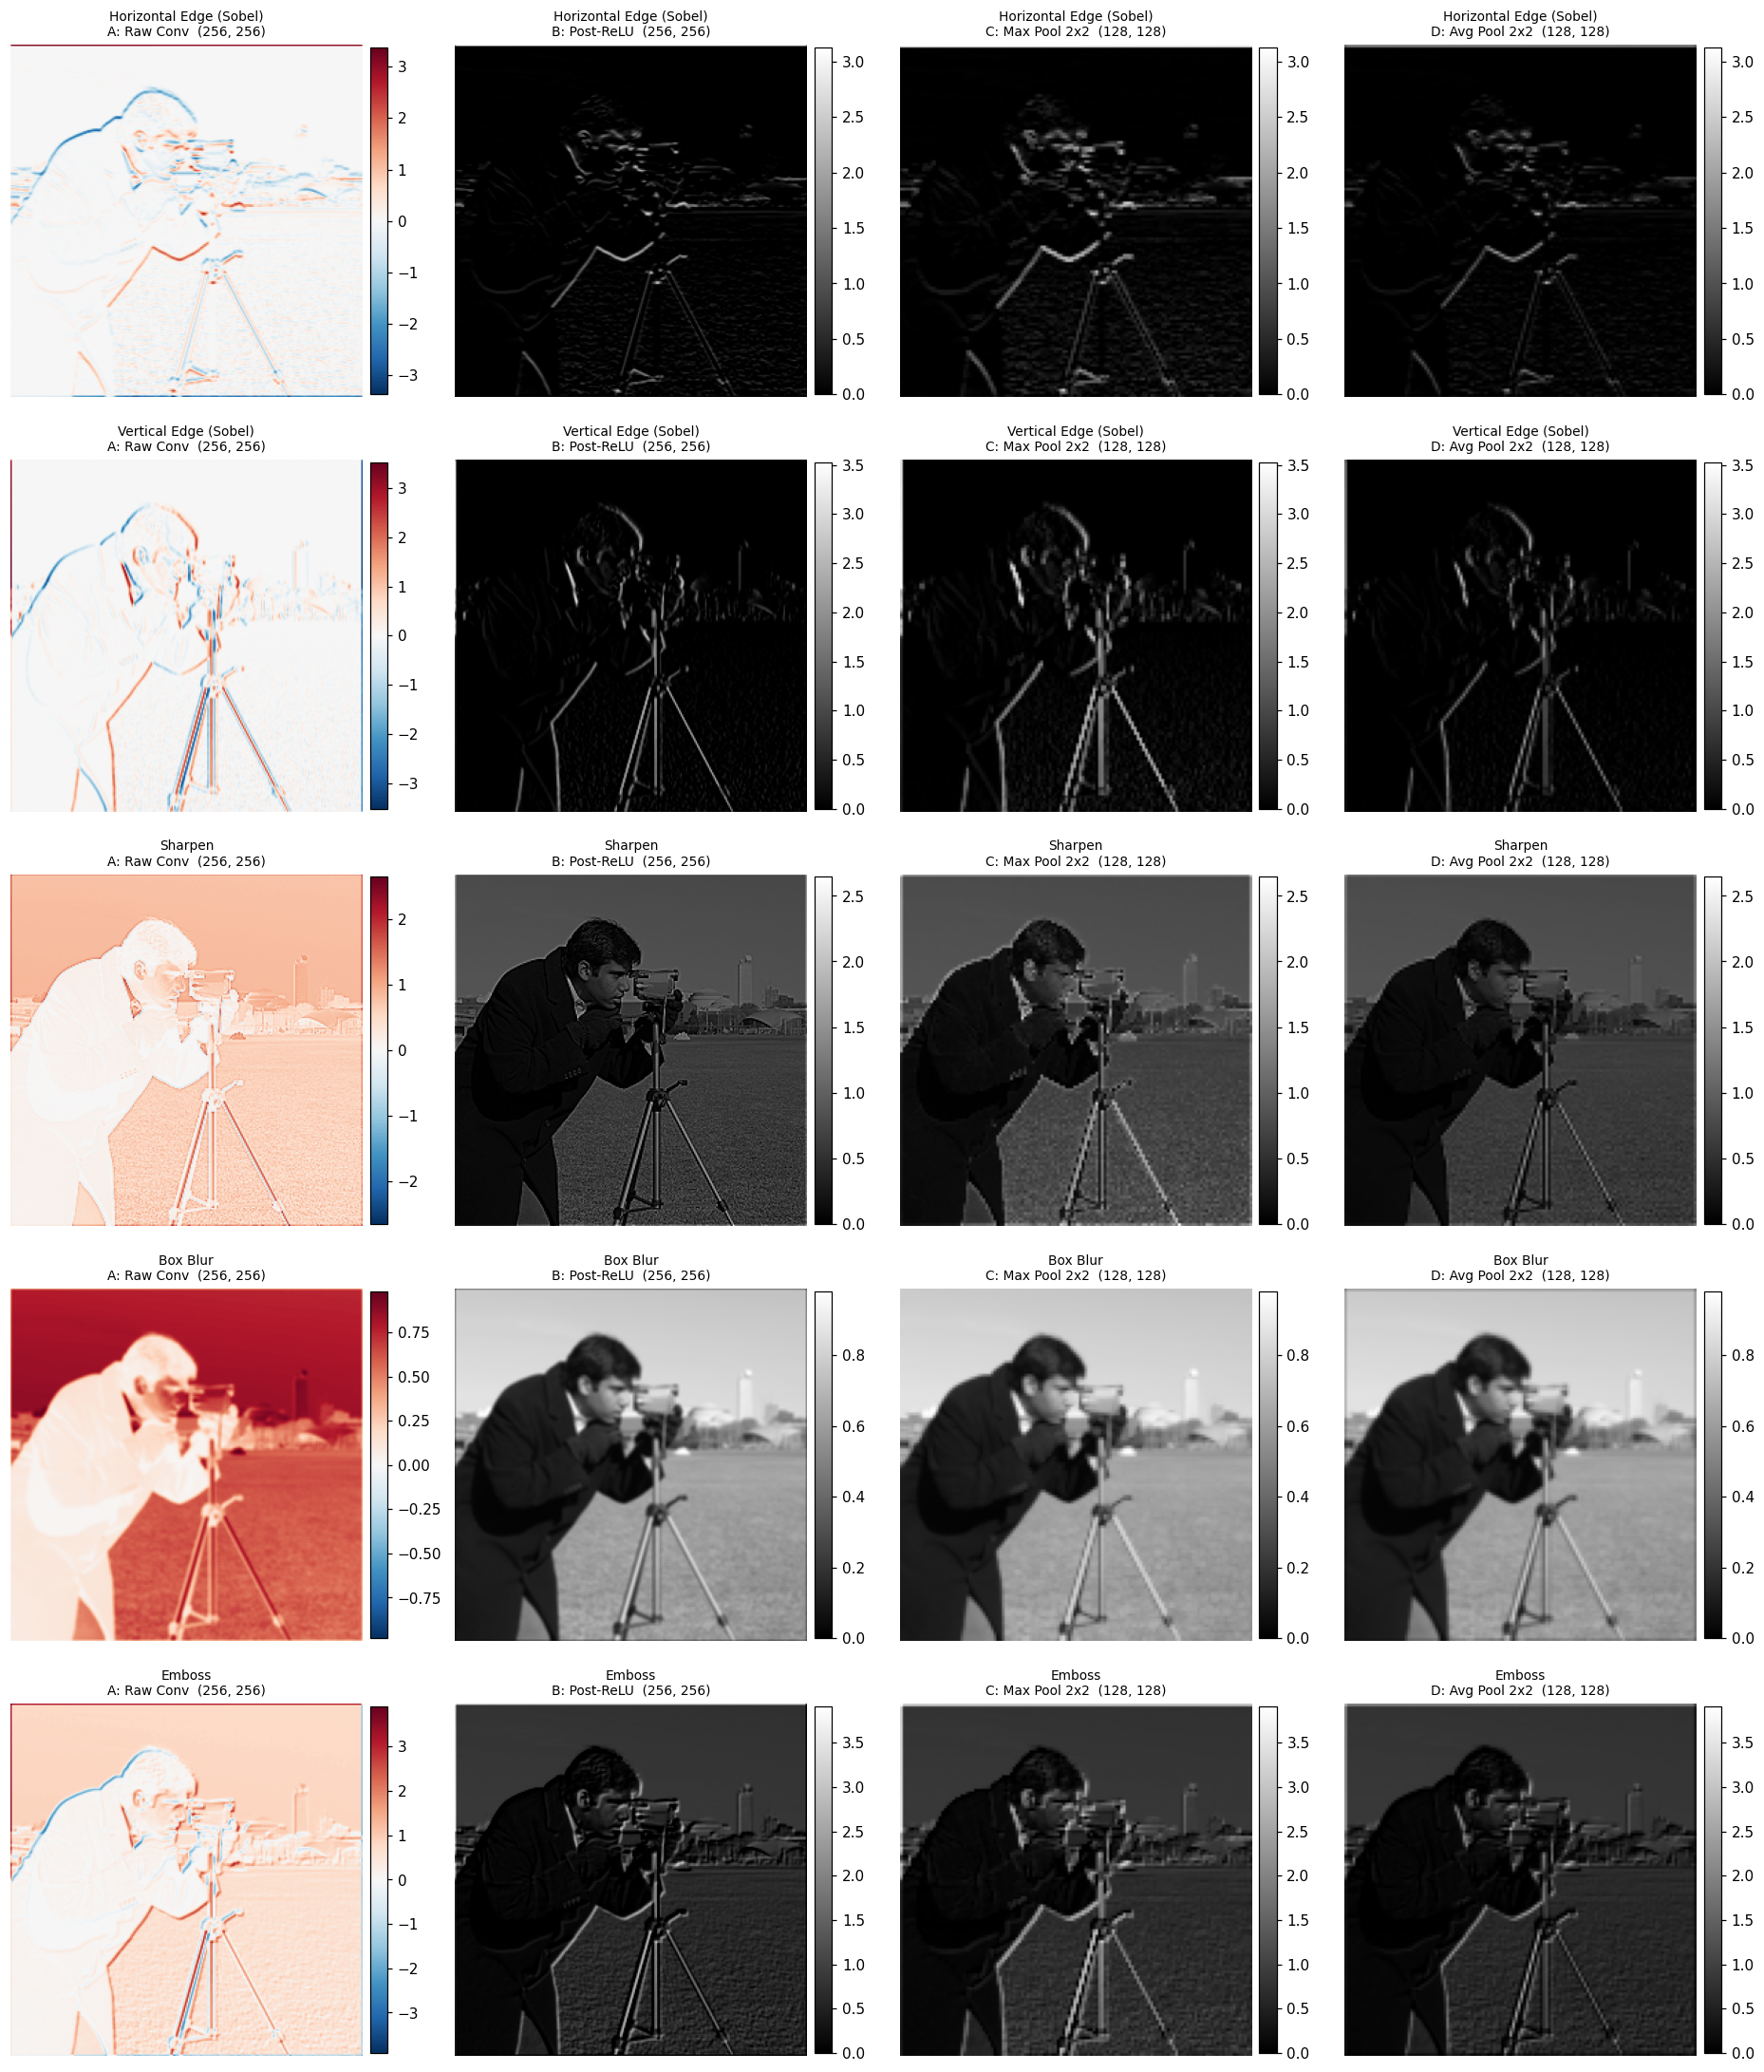

In [5]:
stage_titles = ["A: Raw Conv", "B: Post-ReLU", "C: Max Pool 2x2", "D: Avg Pool 2x2"]
fig, axes = plt.subplots(5, 4, figsize=(17, 20))
for r, (name, st) in enumerate(results.items()):
    amax = np.abs(st['A']).max()
    bmax = st['B'].max() if st['B'].max() > 0 else 1
    for c, key in enumerate("ABCD"):
        ax = axes[r, c]
        if key == 'A':
            im = ax.imshow(st[key], cmap='RdBu_r', vmin=-amax, vmax=amax)
        else:
            im = ax.imshow(st[key], cmap='gray', vmin=0, vmax=bmax)
        ax.set_title(f"{name}\n{stage_titles[c]}  {st[key].shape}", fontsize=9)
        ax.axis('off')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
plt.tight_layout()
plt.savefig("grid_5x4.png", dpi=130, bbox_inches='tight')
plt.show()

### Quantitative evidence for the viva (read these numbers next to your grid)

In [6]:
print(f"{'Filter':26s} {'%neg (A)':>9s} {'%zero after ReLU':>17s} {'max A':>8s} {'min A':>8s} {'maxpool mean':>13s} {'avgpool mean':>13s} {'maxpool peak':>13s} {'avgpool peak':>13s}")
for name, st in results.items():
    A, B, C_, D = st['A'], st['B'], st['C'], st['D']
    print(f"{name:26s} {100*(A<0).mean():9.1f} {100*(B==0).mean():17.1f} {A.max():8.2f} {A.min():8.2f} "
          f"{C_.mean():13.3f} {D.mean():13.3f} {C_.max():13.3f} {D.max():13.3f}")

Filter                      %neg (A)  %zero after ReLU    max A    min A  maxpool mean  avgpool mean  maxpool peak  avgpool peak
Horizontal Edge (Sobel)         41.1              41.1     3.13    -3.37         0.128         0.069         3.128         2.282
Vertical Edge (Sobel)           51.7              51.7     3.53    -3.34         0.146         0.081         3.527         2.638
Sharpen                          3.6               3.6     2.64    -0.88         0.613         0.520         2.645         1.630
Box Blur                         0.0               0.0     0.98     0.01         0.519         0.503         0.980         0.971
Emboss                           6.9               6.9     3.91    -2.90         0.650         0.540         3.912         2.737


## Part II — Architecture comparison & parameter audit

Both models: input 32×32×3 → Conv1 (5 filters) → Pool → Conv2 (10 filters) → Pool → **Global Average Pooling** → Dense(10).

**Formula:** params per conv layer = (Kh × Kw × Cin + 1) × Cout; Dense = (inputs + 1) × outputs. Pooling and GAP have 0 parameters.

### Hand calculation

**Model A (3×3, max pooling)**
- Conv1: (3 × 3 × 3 + 1) × 5 = 28 × 5 = **140**
- Pool: 0
- Conv2: (3 × 3 × 5 + 1) × 10 = 46 × 10 = **460**
- Pool + GAP: 0
- Dense: (10 + 1) × 10 = **110**
- **Total A = 140 + 460 + 110 = 710**

**Model B (5×5, average pooling)**
- Conv1: (5 × 5 × 3 + 1) × 5 = 76 × 5 = **380**
- Pool: 0
- Conv2: (5 × 5 × 5 + 1) × 10 = 126 × 10 = **1260**
- Pool + GAP: 0
- Dense: (10 + 1) × 10 = **110**
- **Total B = 380 + 1260 + 110 = 1750**

Now verify with code.

In [7]:
def conv_params(k, cin, cout):  return (k*k*cin + 1) * cout
def dense_params(i, o):         return (i + 1) * o

manual_A = conv_params(3,3,5) + conv_params(3,5,10) + dense_params(10,10)
manual_B = conv_params(5,3,5) + conv_params(5,5,10) + dense_params(10,10)
print("Manual A:", manual_A, "| Manual B:", manual_B)

Manual A: 710 | Manual B: 1750


In [8]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_model(k, pool):
    P = layers.MaxPooling2D if pool == 'max' else layers.AveragePooling2D
    return models.Sequential([
        layers.Input((32, 32, 3)),
        layers.Conv2D(5,  k, activation='relu'),
        P(2, strides=2),
        layers.Conv2D(10, k, activation='relu'),
        P(2, strides=2),
        layers.GlobalAveragePooling2D(),
        layers.Dense(10, activation='softmax'),
    ])

model_A = build_model(3, 'max')
model_B = build_model(5, 'avg')
print("===== MODEL A ====="); model_A.summary()
print("===== MODEL B ====="); model_B.summary()

===== MODEL A =====


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 5)      │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 10)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710 (2.77 KB)

 Trainable params: 710 (2.77 KB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 5)      │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 5)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 10, 10, 10)     │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 10)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 10)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,750 (6.84 KB)

 Trainable params: 1,750 (6.84 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
import pandas as pd
audit = pd.DataFrame([
    ["Model A (Standard)",     "Conv1: 5, Conv2: 10", "3 x 3", "Max Pooling (2x2, s2)", manual_A, model_A.count_params()],
    ["Model B (Large Kernel)", "Conv1: 5, Conv2: 10", "5 x 5", "Avg Pooling (2x2, s2)", manual_B, model_B.count_params()],
], columns=["Model", "Conv Architecture", "Kernel", "Pooling", "Manual Count", "Code Output"])
assert manual_A == model_A.count_params() and manual_B == model_B.count_params()
display(audit)

,Model,Conv Architecture,Kernel,Pooling,Manual Count,Code Output
0,Model A (Standard),"Conv1: 5, Conv2: 10",3 x 3,"Max Pooling (2x2, s2)",710,710
1,Model B (Large Kernel),"Conv1: 5, Conv2: 10",5 x 5,"Avg Pooling (2x2, s2)",1750,1750


## Part III — Critical thinking & viva answers

### Question 1 — ReLU "blackout" and alternatives


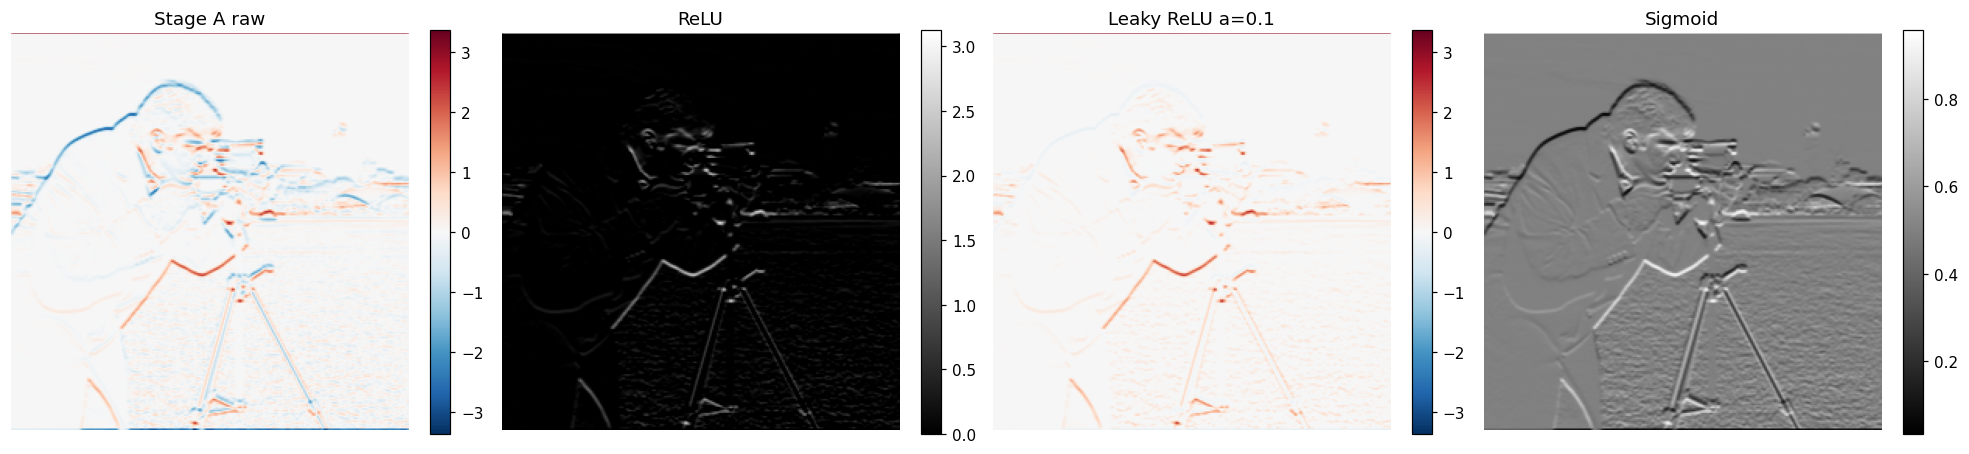

min/max  ReLU: 0.00/3.13 | Leaky: -0.34/3.13 | Sigmoid: 0.033/0.958
Sigmoid value at zero response (flat areas): 0.5


In [10]:
A = results["Horizontal Edge (Sobel)"]['A']
leaky   = np.where(A > 0, A, 0.1*A)
sigmoid = 1/(1+np.exp(-A))
fig, ax = plt.subplots(1, 4, figsize=(18, 4.5))
panels = [("Stage A raw", A, 'RdBu_r', np.abs(A).max()), ("ReLU", relu(A), 'gray', None),
          ("Leaky ReLU a=0.1", leaky, 'RdBu_r', np.abs(A).max()), ("Sigmoid", sigmoid, 'gray', None)]
for a, (t, m, cm, lim) in zip(ax, panels):
    im = a.imshow(m, cmap=cm, **({'vmin': -lim, 'vmax': lim} if lim else {})); a.set_title(t); a.axis('off'); fig.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()
print("min/max  ReLU: %.2f/%.2f | Leaky: %.2f/%.2f | Sigmoid: %.3f/%.3f"
      % (relu(A).min(), relu(A).max(), leaky.min(), leaky.max(), sigmoid.min(), sigmoid.max()))
print("Sigmoid value at zero response (flat areas):", 1/(1+np.exp(0)))

### Question 2 — Max vs. average pooling


Original min: 0.0 | MaxPool min: 255.0 | AvgPool min: 63.75


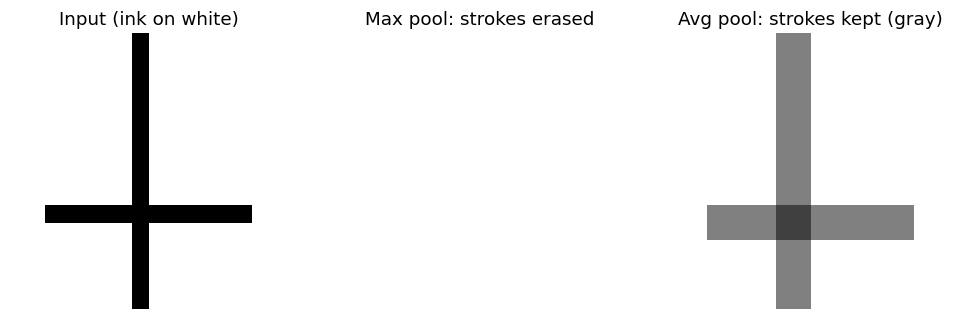

In [11]:
ink = np.full((16, 16), 255.0)
ink[:, 7] = 0          # a 1-pixel-wide vertical dark stroke
ink[10, 2:14] = 0      # a 1-pixel-wide horizontal dark stroke
mp, ap = pool2d(ink, mode='max'), pool2d(ink, mode='avg')
print("Original min:", ink.min(), "| MaxPool min:", mp.min(), "| AvgPool min:", ap.min())
fig, ax = plt.subplots(1, 3, figsize=(11, 3.8))
for a, m, t in zip(ax, [ink, mp, ap], ["Input (ink on white)", "Max pool: strokes erased", "Avg pool: strokes kept (gray)"]):
    a.imshow(m, cmap='gray', vmin=0, vmax=255); a.set_title(t); a.axis('off')
plt.show()

### Question 3 — Parameter explosion & receptive-field equivalence


In [12]:
def stacked(k, cin, cout, n=2):  # n stacked kxk layers, intermediate channels = cin
    return conv_params(k, cin, cin)*(n-1) + conv_params(k, cin, cout)
inc = (manual_B - manual_A) / manual_A * 100
print(f"Increase A->B: {inc:.2f}%  ({manual_A} -> {manual_B})")
c1 = conv_params(5,3,5) - stacked(3,3,5);  c2 = conv_params(5,5,10) - stacked(3,5,10)
print("Saving Conv1:", c1, "| Saving Conv2:", c2, "| Total saving:", c1+c2,
      f"= {(c1+c2)/manual_B*100:.1f}% of Model B")

Increase A->B: 146.48%  (710 -> 1750)
Saving Conv1: 156 | Saving Conv2: 570 | Total saving: 726 = 41.5% of Model B


### Question 4 — Order invariance: Conv→ReLU→MaxPool vs Conv→MaxPool→ReLU


In [13]:
patch = np.array([[-3., 2.], [-1., -5.]])
print("ReLU->Max:", relu(patch).max(), "| Max->ReLU:", relu(patch.max()))
patch2 = np.array([[-4., 2.], [-1., -3.]])
print("Avg case  ReLU->Avg:", relu(patch2).mean(), "| Avg->ReLU:", relu(patch2.mean()))

# empirical check on the real feature map
A = results["Vertical Edge (Sobel)"]['A']
order1 = pool2d(relu(A), mode='max'); order2 = relu(pool2d(A, mode='max'))
print("Max-pool orders identical on real map:", np.allclose(order1, order2))

ReLU->Max: 2.0 | Max->ReLU: 2.0
Avg case  ReLU->Avg: 0.5 | Avg->ReLU: 0.0
Max-pool orders identical on real map: True
